In [1]:
from pathlib import Path
import sys
import importlib

# Locate the capsule/project root independently of the working directory.
# In Code Ocean this notebook lives in /code/<subfolder>/ and the data in /data.
# Locally it lives in <repo>/code/<subfolder>/ with the data in <repo>/data.
def _find_code_dir(start):
    for p in [start, *start.parents]:
        if (p / "utils.py").is_file():
            return p
        if (p / "code" / "utils.py").is_file():
            return p / "code"
    raise FileNotFoundError("could not find code/utils.py")

CODE_DIR = _find_code_dir(Path.cwd().resolve())
DATA_DIR = CODE_DIR.parent / "data"
# Add the code folder to sys.path so that `utils`, `statistic_checks` and
# `mot_analysis` can be imported
sys.path.append(str(CODE_DIR))

import pandas as pd
import numpy as np
from statistic_checks import article_plots
importlib.reload(article_plots)

<module 'statistic_checks.article_plots' from 'C:\\Users\\idol\\Desktop\\bigProjects\\EyeTrackingAnalysis\\statistic_checks\\article_plots.py'>

In [2]:
# 1. Visual Search: Reaction Time
rt_stats_phases_2_3 = {
    "p-value": ".002 **",
    "β (Estimate)": "0.273",
    "Note": "Novices ~31% slower\n(Phases 2 & 3)"
}
rt_stats_phase1 = {
    "p-value": ".312 (ns)",
    "Note": "Phase 1"
}

# 2. Visual Search: Fixation Duration
fix_dur_stats = {
    "p-value": ".028 *",
    "β (Estimate)": "14.2 ms",
    "Note": "All Phases"
}

# 3. Visual Search: Initiation Time
init_time_stats = {
    "p-value": ".009 **",
    "β (Estimate)": "34.9 ms",
    "Note": "All Phases"
}



In [3]:
import re

simple_df = pd.read_csv(DATA_DIR / "simple_df_search.csv")
simple_df = simple_df[simple_df["trial_id"] <= 71]
simple_df["group"] = simple_df["group"].replace("Experienced", "ATCs")
simple_df["group"] = simple_df["group"].replace("Experts", "ATCs")
simple_df = simple_df.rename(columns={
    'pid': 'participant_id'
})
conditions = [(1,7),(8,15),(16,23),(25,31),(32,39),(40,47),(49,55),(56,63),(64,71),(72,77)]
simple_df = simple_df[simple_df["participant_id"] != 0]

def clean_coordinate_strings(coord):
    """Extracts x and y float values from a string representation."""
    # If it's already a proper list or tuple, leave it alone
    if isinstance(coord, (list, tuple)):
        return coord
        
    if isinstance(coord, str):
        # Find all numbers that contain a decimal point
        floats = re.findall(r"[-+]?\d+\.\d+", coord)
        if len(floats) >= 2:
            return (float(floats[0]), float(floats[1]))
            
    return (np.nan, np.nan)

# Apply this to your DataFrame before running any plotting or summary functions:
simple_df['start_pos'] = simple_df['start_pos'].apply(clean_coordinate_strings)
simple_df['end_pos'] = simple_df['end_pos'].apply(clean_coordinate_strings)

def map_condition(trial_id):
    for idx, (start, end) in enumerate(conditions):
        if start <= trial_id <= end:
            return f"Cond_{idx}" # Or simply idx + 1
    return None

# 3. Apply the mapping to create the 'condition' column
simple_df['condition'] = simple_df['trial_id'].apply(map_condition)
simple_df = simple_df[simple_df['condition'] != "Cond_9"]
# simple_df = simple_df[simple_df['condition'] != "Cond_8"]

simple_df = simple_df.dropna()


# simple_df = simple_df[simple_df['condition'].isin(['Cond_4','Cond_5','Cond_7' 'Cond_7', 'Cond_8'])]
# simple_df = simple_df[~simple_df['condition'].isin(['Cond_4','Cond_5','Cond_7' 'Cond_7', 'Cond_8'])]


In [4]:
from utils import *

# Create the DataFrame
rt_df = pd.read_csv(DATA_DIR / "search_performance_long.csv")

conditions = [(1,7),(8,15),(16,23),(25,31),(32,39),(40,47),(49,55),(56,63),(64,71),(72,77)]

def map_condition(trial_id):
    for idx, (start, end) in enumerate(conditions):
        if start <= trial_id <= end:
            return f"Cond_{idx}" # Or simply idx + 1
    return None

# 3. Apply the mapping to create the 'condition' column
rt_df['condition'] = rt_df['trial_id'].apply(map_condition)

rt_df = rt_df[rt_df['condition'] != 'Cond_9']
# rt_df = rt_df[rt_df['condition'].isin(['Cond_3','Cond_4','Cond_5','Cond_6', 'Cond_7', 'Cond_8'])]
rt_df = rt_df.dropna()
print(rt_df["participant_id"].unique())

0.7494391486306472
[ 0  1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20 21 22 23
 24 25]


Error importing in API mode: ImportError('On Windows, cffi mode "ANY" is only "ABI".')
Trying to import in ABI mode.
C:\Users\idol\Desktop\bigProjects\EyeTrackingAnalysis\statistic_checks\article_plots.py:310: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


Means - Novices: 1.632, ATCs: 1.359 | Linear Diff: 0.273 | % Diff: 16.72%


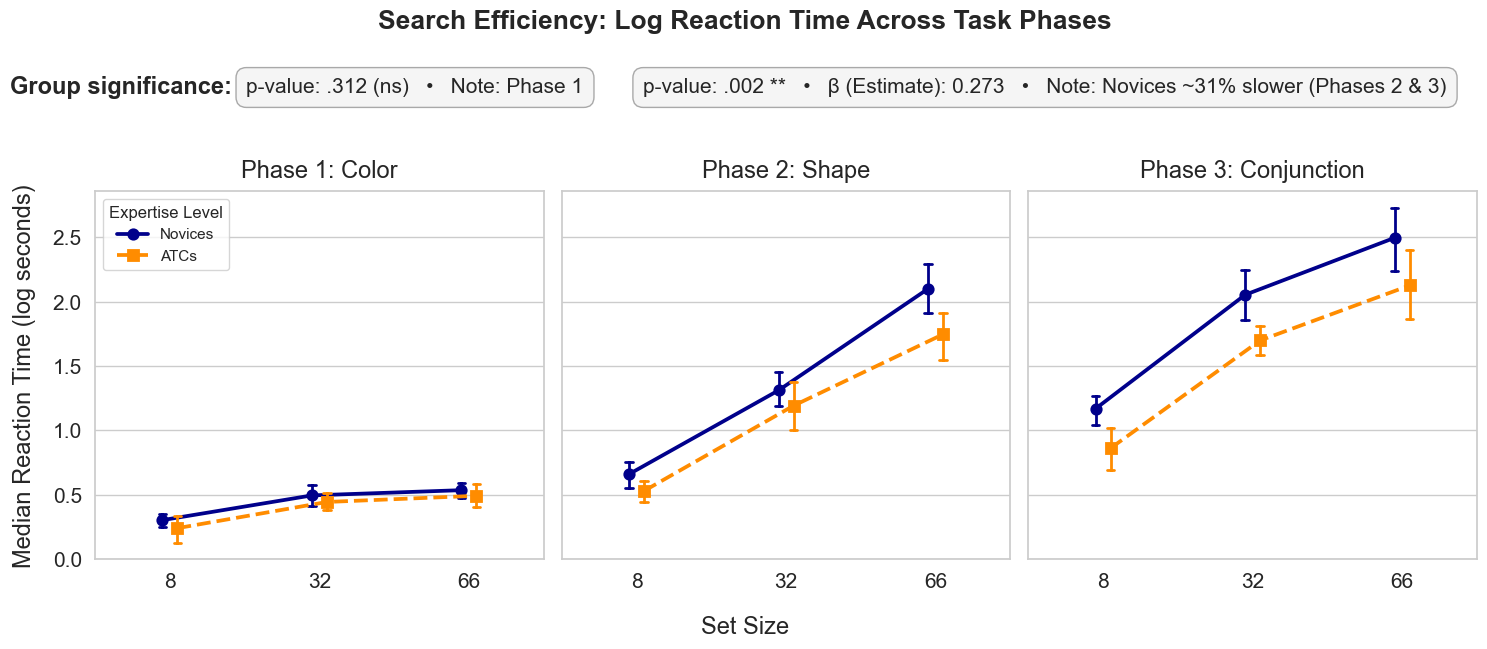

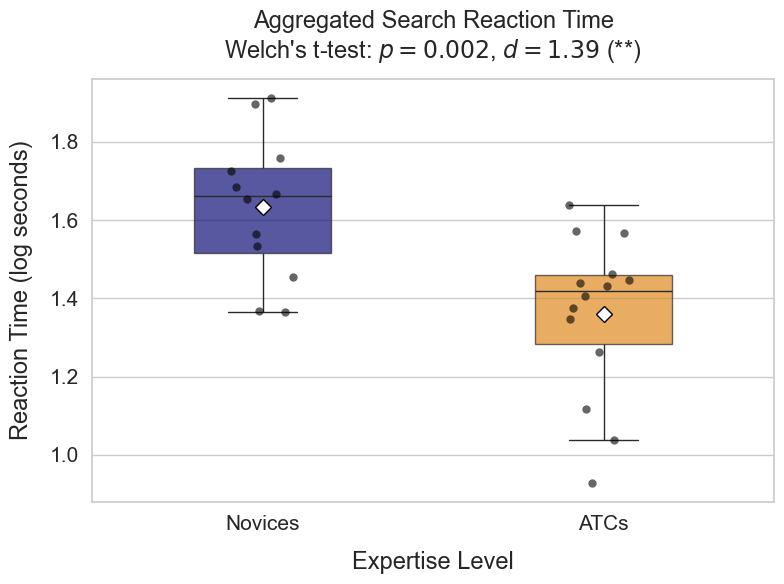

In [5]:
importlib.reload(article_plots)
def log_replace_30_median(x):
    arr = np.where(np.array(x) == -1, 30.0, x)
    return np.median(np.log(arr))
from statistic_checks import MixedEffectStatistics, GLMs, article_plots
agg_df = MixedEffectStatistics.condition_aggregator(rt_df,'reaction_time', agg_func= log_replace_30_median)

fig, ax = article_plots.plot_phase_subplots_split_stats(
    df=agg_df, 
    feature='log_replace_30_median_reaction_time', 
    y_label='Median Reaction Time (log seconds)',
    plot_title='Search Efficiency: Log Reaction Time Across Task Phases',
    stat_box_phase1=rt_stats_phase1,
    stat_box_phase23=rt_stats_phases_2_3
)

# fig.savefig("../figures/features_per_condition/search_log_rt.png", dpi=300, bbox_inches='tight')

agg_df = agg_df[agg_df['condition'].isin(['Cond_3','Cond_4','Cond_5','Cond_6', 'Cond_7', 'Cond_8'])]


fig, ax, per_participant_rt = article_plots.plot_aggregated_feature(agg_df, 'log_replace_30_median_reaction_time', 'Reaction Time (log seconds)', "Aggregated Search Reaction Time")
# fig.savefig("../figures/aggregated_features/rt_aggregated.png", dpi=300, bbox_inches='tight')

### Fixation Duration

In [6]:
from scipy.stats import gmean, trim_mean, skew, kurtosis

# Factory function to generate specific trimmed means
def create_trimmed_aggregator(proportion):
    def custom_trim(x):
        # scipy's trim_mean cuts 'proportion' from BOTH ends
        return trim_mean(x, proportiontocut=proportion)
    # Dynamically set the function's name for your condition_aggregator
    pct = int(proportion * 100)
    custom_trim.__name__ = f"trimmed_mean_{pct}pct"
    
    return custom_trim# 1. Define all your aggregators in a list
aggregators = [
    np.mean, 
    np.median, 
    gmean, 
    create_trimmed_aggregator(0.1),
    create_trimmed_aggregator(0.2),
    create_trimmed_aggregator(0.3),
    np.std,
    skew]

In [7]:
from statistic_checks import GLMs, MixedEffectStatistics
from scipy.stats import gmean
importlib.reload(GLMs)
# 1. Filter for saccades and create a clean copy
fix_df = simple_df[simple_df['event_type'] == 'fixation'].copy()
fix_df['duration_ms'] = 1000 * fix_df['duration_sec']

# remove first and last fixations
fix_df = fix_df.groupby(['participant_id', 'trial_id'], group_keys=False).apply(
        lambda x: x.iloc[1:-1] if len(x) > 2 else x.iloc[0:0]
    ).reset_index(drop=True)

GLMs.aggregators_pipeline(fix_df, "duration_ms", aggregators)



C:\Users\idol\AppData\Local\Temp\ipykernel_24784\3027892075.py:9: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  fix_df = fix_df.groupby(['participant_id', 'trial_id'], group_keys=False).apply(
C:\Users\idol\Desktop\bigProjects\EyeTrackingAnalysis\statistic_checks\GLMs.py:103: FutureWarning: The provided callable <function mean at 0x0000010479FA68C0> is currently using SeriesGroupBy.mean. In a future version of pandas, the provided callable will be used directly. To keep current behavior pass the string "mean" instead.
  agg_df = df.groupby(group_cols)[value_col].agg(agg_func).reset_index()
C:\Users\idol\Desktop\bigProjects\EyeTrackingAnalysis\statistic_checks\GLMs.py:103: FutureWarning: The provided c

                    group_coef  group_p_value  marginal_r2  conditional_r2
aggregator                                                                
mean                   15.8379         0.0229       0.4107          0.7126
median                 13.3203         0.0320       0.4745          0.7783
gmean                  14.1548         0.0284       0.4249          0.7793
trimmed_mean_10pct     14.4803         0.0267       0.4215          0.7557
trimmed_mean_20pct     13.3885         0.0346       0.4439          0.7787
trimmed_mean_30pct     13.2014         0.0350       0.4595          0.7898
std                     9.2328         0.0688       0.4684          0.5482
skew                    0.1755         0.4810       0.4348          0.5098


,group_coef,group_p_value,marginal_r2,conditional_r2
aggregator,,,,
mean,15.8379,0.0229,0.4107,0.7126
median,13.3203,0.0320,0.4745,0.7783
gmean,14.1548,0.0284,0.4249,0.7793
trimmed_mean_10pct,14.4803,0.0267,0.4215,0.7557
trimmed_mean_20pct,13.3885,0.0346,0.4439,0.7787
trimmed_mean_30pct,13.2014,0.0350,0.4595,0.7898
std,9.2328,0.0688,0.4684,0.5482
skew,0.1755,0.4810,0.4348,0.5098


C:\Users\idol\Desktop\bigProjects\EyeTrackingAnalysis\statistic_checks\article_plots.py:310: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


Means - Novices: 163.705, ATCs: 149.550 | Linear Diff: 14.155 | % Diff: 8.65%


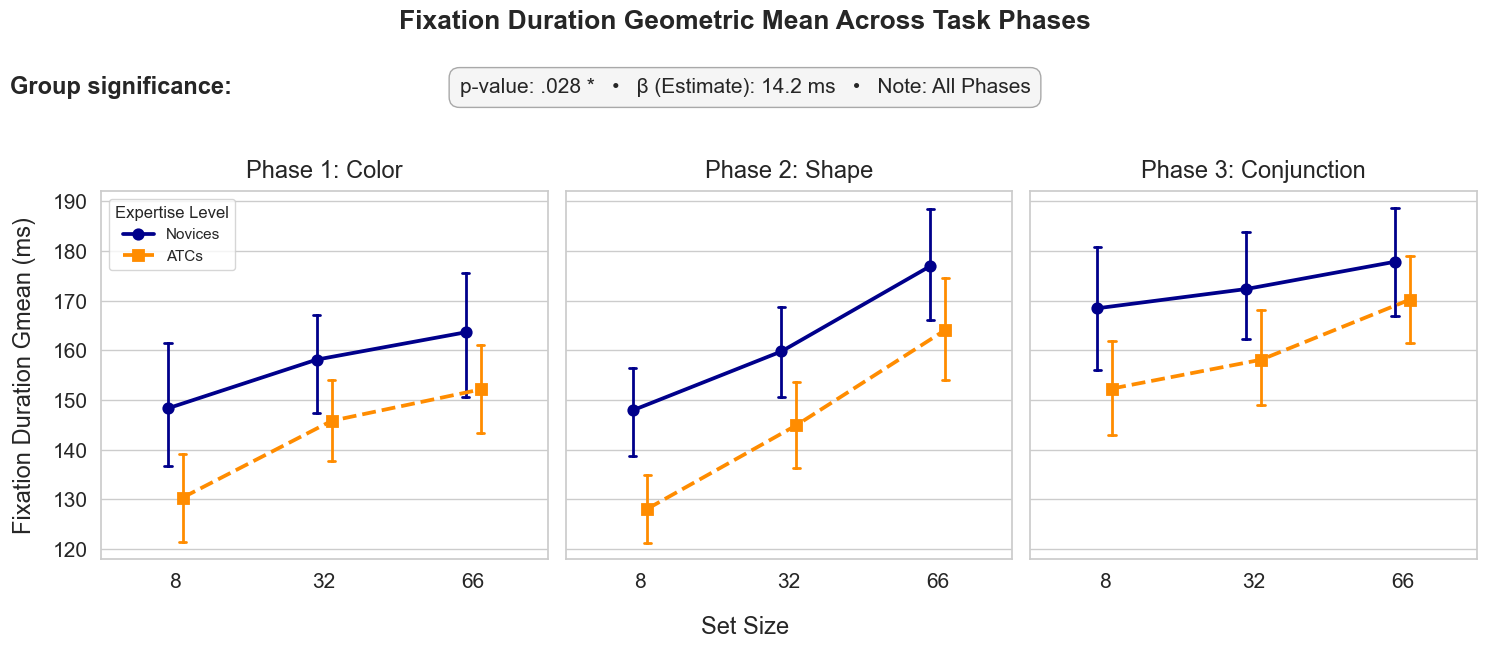

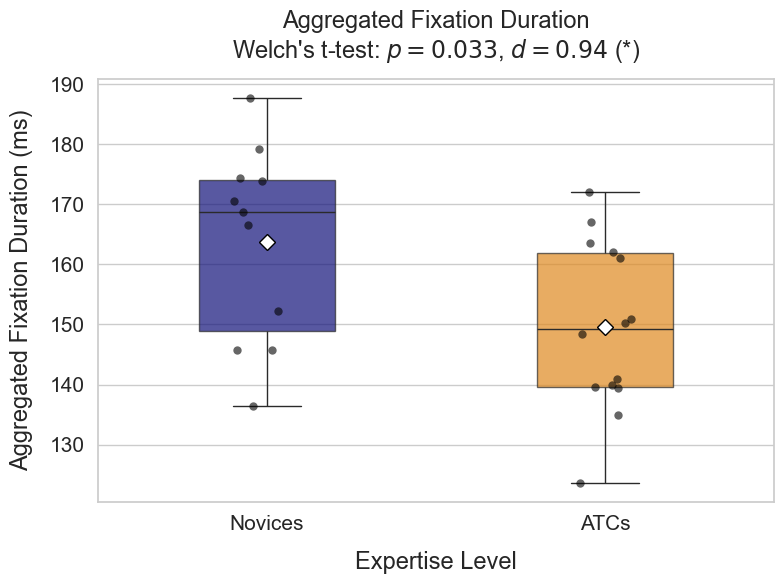

In [8]:
# plot
from statistic_checks import plot_utils, article_plots, MixedEffectStatistics
importlib.reload(plot_utils)
importlib.reload(article_plots)
col_name = "duration_ms"
agg_func = gmean

func_name = agg_func.__name__
val_col_name = f"{func_name}_{col_name}"
df_agg = MixedEffectStatistics.condition_aggregator(
        df=fix_df,  
        value_col=col_name, 
        agg_func= agg_func
    )

fig, ax = article_plots.plot_phase_subplots(
    df=df_agg, 
    feature=val_col_name, 
    y_label="Fixation Duration Gmean (ms)",  
    plot_title="Fixation Duration Geometric Mean Across Task Phases",
    stat_box=fix_dur_stats
)
# fig.savefig("../figures/features_per_condition/fixation_duration_gmean.png", dpi=300, bbox_inches='tight')


fig, ax, per_participant_fixation_duration = article_plots.plot_aggregated_feature(
    df_agg, 
    val_col_name, 
    "Aggregated Fixation Duration (ms)",  
    "Aggregated Fixation Duration"
)

# fig.savefig("../figures/aggregated_features/fixation_duration.png", dpi=300, bbox_inches='tight')

In [9]:
# col_name = "duration_ms"
# agg_func = gmean

# func_name = agg_func.__name__
# val_col_name = f"{func_name}_{col_name}"
# df_agg = GLMs.weighted_condition_aggregator(
#         df=fix_df,  
#         value_col=col_name,
#         weight_method = 'log_count', 
#         agg_func= agg_func,

#     )
# per_participant_fixation_duration = GLMs.extract_lmm_participant_scores(df_agg, val_col_name, weight_col='weight')


### Initiation Time

In [10]:
# 1. Filter for saccades and create a clean copy
initiation_time_df = simple_df[simple_df['event_type'] == 'fixation'].copy()

# remove first and last fixations
initiation_time_df = initiation_time_df.groupby(['participant_id', 'trial_id'], group_keys=False).apply(
        lambda x: x.iloc[0]).reset_index(drop=True)

initiation_time_df = initiation_time_df.rename(columns = {"duration_sec" : "initiation_time"})
initiation_time_df['initiation_time_ms'] = 1000 * initiation_time_df['initiation_time']

# print(initiation_time_df)

C:\Users\idol\AppData\Local\Temp\ipykernel_24784\773955697.py:5: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  initiation_time_df = initiation_time_df.groupby(['participant_id', 'trial_id'], group_keys=False).apply(


C:\Users\idol\Desktop\bigProjects\EyeTrackingAnalysis\statistic_checks\MixedEffectStatistics.py:20: FutureWarning: The provided callable <function median at 0x000001047A1141F0> is currently using SeriesGroupBy.median. In a future version of pandas, the provided callable will be used directly. To keep current behavior pass the string "median" instead.
  )[value_col].agg(agg_func).reset_index()


{'group_coef': 34.945526695525324, 'group_p_value': 0.008674, 'marginal_r2': np.float64(0.38954100653828333), 'conditional_r2': np.float64(0.6507595109762901)}


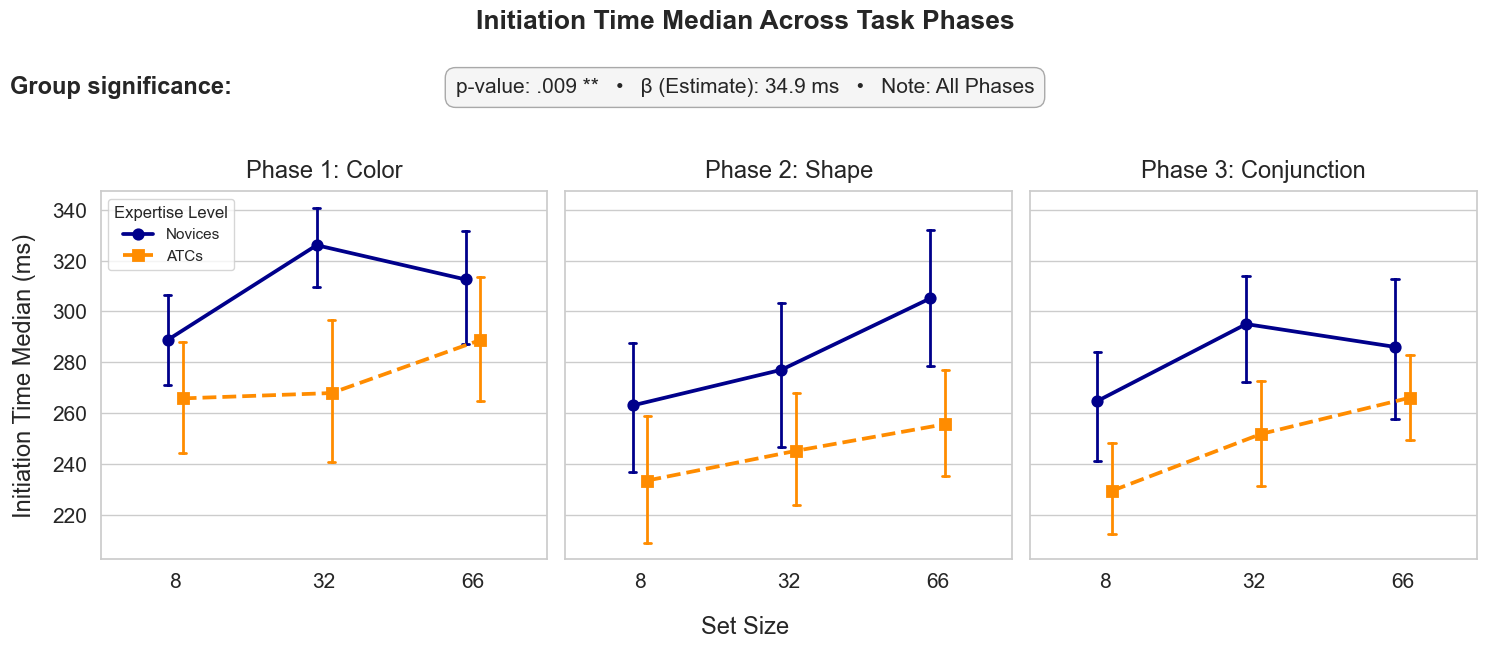

In [11]:
from statistic_checks import plot_utils, article_plots, MixedEffectStatistics
from statistic_checks import GLMs, MixedEffectStatistics
importlib.reload(GLMs)


importlib.reload(plot_utils)
importlib.reload(article_plots)
col_name = "initiation_time_ms"
agg_func = np.median

func_name = agg_func.__name__
val_col_name = f"{func_name}_{col_name}"
df_agg = MixedEffectStatistics.condition_aggregator(
        df=initiation_time_df,  
        value_col=col_name, 
        agg_func= agg_func
    )

model , extras= GLMs.run_pymer_lmm(df_agg,val_col_name)
print(extras)

fig, ax = article_plots.plot_phase_subplots(
    df=df_agg, 
    feature=val_col_name, 
    y_label="Initiation Time Median (ms)",  
    plot_title="Initiation Time Median Across Task Phases",
    stat_box=init_time_stats
)
# fig.savefig("../figures/features_per_condition/initiation_time_median.png", dpi=300, bbox_inches='tight')



C:\Users\idol\Desktop\bigProjects\EyeTrackingAnalysis\statistic_checks\GLMs.py:103: FutureWarning: The provided callable <function median at 0x000001047A1141F0> is currently using SeriesGroupBy.median. In a future version of pandas, the provided callable will be used directly. To keep current behavior pass the string "median" instead.
  agg_df = df.groupby(group_cols)[value_col].agg(agg_func).reset_index()
C:\Users\idol\Desktop\bigProjects\EyeTrackingAnalysis\statistic_checks\article_plots.py:310: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


Means - Novices: 290.949, ATCs: 256.004 | Linear Diff: 34.946 | % Diff: 12.01%


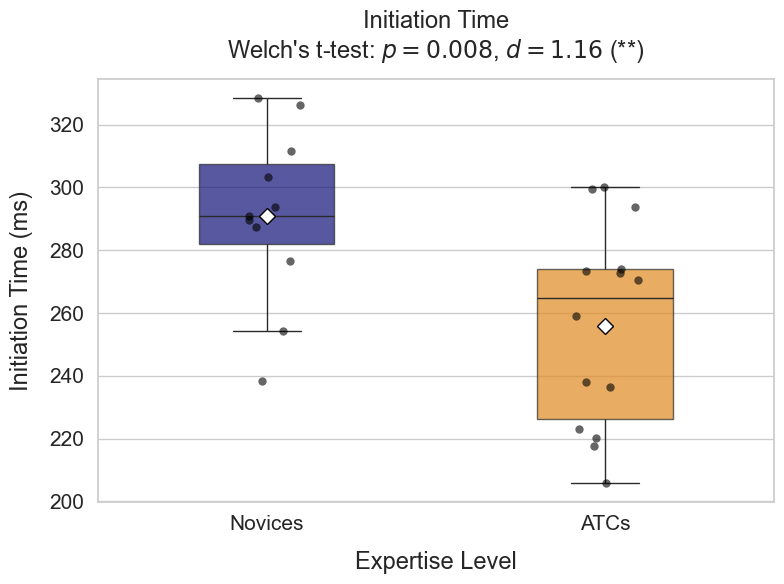

In [12]:
df_agg = GLMs.weighted_condition_aggregator(
        df=initiation_time_df,  
        value_col="initiation_time_ms",
        agg_func= np.median
    )
fig, ax, per_participant_initiation_time = article_plots.plot_aggregated_feature(
    df_agg, 
    "median_initiation_time_ms", 
    "Initiation Time (ms)",  
    "Initiation Time"
)
# fig.savefig("../figures/aggregated_features/initiation_time.png", dpi=300, bbox_inches='tight')



# per_participant_initiation_time = GLMs.extract_lmm_participant_scores(df_agg, "median_initiation_time_ms")
# fig, ax = article_plots.plot_aggregated_feature(
#     per_participant_initiation_time, 
#     "median_initiation_time_ms_zscore", 
#     "Initiation Time Z-Score",  
#     "Adjusted Search Initiation Time"
# )
# fig.savefig("../figures/aggregated_features/initiation_time_z_score.png", dpi=300, bbox_inches='tight')

### Combined Score

C:\Users\idol\Desktop\bigProjects\EyeTrackingAnalysis\statistic_checks\article_plots.py:310: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


Means - Novices: -0.570, ATCs: 0.448 | Linear Diff: -1.018 | % Diff: 178.57%


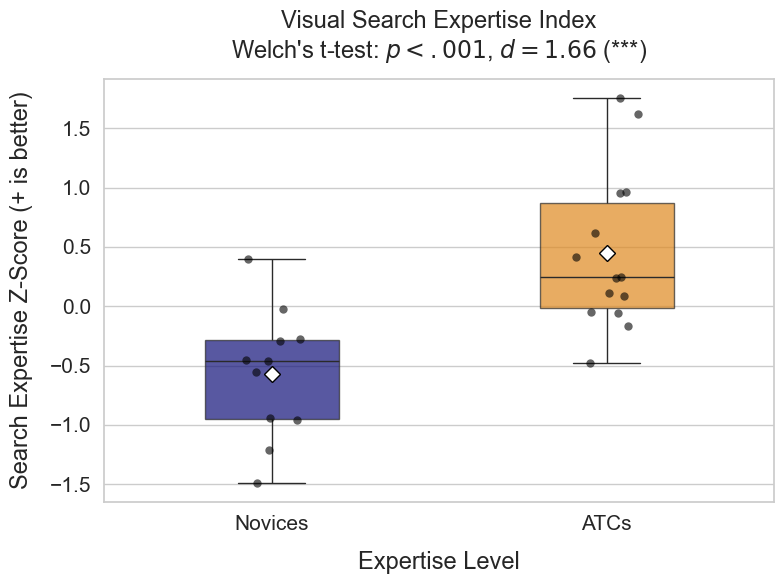

In [13]:
from functools import reduce
importlib.reload(article_plots)
from scipy.stats import zscore
# 1. Put your dataframes in a list
dfs = [per_participant_fixation_duration, per_participant_rt, per_participant_initiation_time]

# 2. Merge them all sequentially on the shared columns
combined_df = reduce(lambda left, right: pd.merge(left, right, on=['participant_id', 'group'], how='inner'), dfs)

# 3. Apply Z-score independently to each target column
cols_to_zscore = [
    'log_replace_30_median_reaction_time', 
    'median_initiation_time_ms', 
    'gmean_duration_ms'
]

# Create new z-scored columns (nan_policy='omit' safely ignores any missing data)
for col in cols_to_zscore:
    combined_df[f'{col}_z'] = zscore(combined_df[col], nan_policy='omit')

# 4. Calculate the aligned Expertise Index using the newly generated z-score columns
combined_df['expertise_index_search'] = (
    (combined_df['log_replace_30_median_reaction_time_z'] * -1) +  # Lower raw time = Better (higher z-score)
    (combined_df['median_initiation_time_ms_z'] * -1) +            # Lower raw time = Better
    (combined_df['gmean_duration_ms_z'] * -1)                      # Lower raw duration = Better
) / 3

fig, ax, _ = article_plots.plot_aggregated_feature(
    combined_df, 
    'expertise_index_search', 
    'Search Expertise Z-Score (+ is better)', 
    'Visual Search Expertise Index'
)
# fig.savefig("../figures/z_score/search_z_score.png", dpi=300, bbox_inches='tight')
# Write next to the notebook locally, or into /results inside Code Ocean
OUT_DIR = Path("/results") if Path("/results").is_dir() else Path.cwd()
combined_df.to_csv(OUT_DIR / "combined_zscore_search.csv", index=False)